In [1]:
%load_ext cuml.accel
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import confusion_matrix, classification_report
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from imblearn.over_sampling import RandomOverSampler
from sklearn.metrics import confusion_matrix, classification_report
import plotly.express as px
import warnings
warnings.filterwarnings('ignore')

In [2]:
def draw_confusion_matrix(cm, title='Confusion Matrix'):
    plt.figure(figsize=(6, 4))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
                xticklabels=['Not Fraud', 'Fraud'], yticklabels=['Not Fraud', 'Fraud'])
    plt.title(title)
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

In [3]:
import kagglehub

path = kagglehub.dataset_download("ealaxi/banksim1")
print("Path to dataset files:", path)

100%|██████████| 13.1M/13.1M [00:00<00:00, 198MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ealaxi/banksim1/versions/1


In [4]:
data = pd.read_csv(path+'/bs140513_032310.csv')

In [5]:
data = data.drop(['zipcodeOri', 'zipMerchant'], axis=1)
data['customer'] = data['customer'].str[1:-1]
data['age'] = data['age'].str[1:-1]
data['gender'] = data['gender'].str[1:-1]
data['merchant'] = data['merchant'].str[1:-1]
data['category'] = data['category'].str.replace('es_', '')
data = data[data['gender'] != 'U']
data['age'] = data['age'].replace('U', '7')
data['age'] = data['age'].astype(float)

In [6]:
def create_amount_thresh(amount):
    if amount <= 500:
        return '0-500'
    elif amount <= 1000:
        return '500-1000'
    elif amount <= 1500:
        return '1000-1500'
    elif amount <= 2000:
        return '1500-2000'
    elif amount <= 2500:
        return '2000-2500'
    elif amount <= 3000:
        return '2500-3000'
    else:
        return '>3000'

In [7]:
data['amount_thresh'] = data['amount'].apply(create_amount_thresh)

In [8]:
customer = data.groupby('customer').size().reset_index(name='customer_total_trans')
customer['customer_ID'] = range(1, len(customer) + 1)

merchant = data.groupby('merchant').size().reset_index(name='merchant_total_trans')
merchant['merchant_ID'] = range(1, len(merchant) + 1)

category = data.groupby('category').size().reset_index(name='category_total_trans')
category['category_ID'] = range(1, len(category) + 1)

amount_thresh = data.groupby('amount_thresh').size().reset_index(name='amount_thresh_total_trans')
amount_thresh['amount_thresh_ID'] = range(1, len(amount_thresh) + 1)

In [9]:
data = data.merge(customer, on='customer').merge(merchant, on='merchant')
data = data.drop(['customer', 'merchant'], axis=1)
data = data.merge(category, on='category').merge(amount_thresh, on='amount_thresh')
data['category'] = data['category_ID']
data['amount_thresh'] = data['amount_thresh_ID']
data = data.drop(['category_ID', 'amount_thresh_ID'], axis=1)

In [10]:
age = data.groupby('age').size().reset_index(name='age_total_trans')
gender = data.groupby('gender').size().reset_index(name='gender_total_trans')
data = data.merge(age, on='age').merge(gender, on='gender')

In [11]:
total_freq = len(data)
data['merchant_total_trans'] = (data['merchant_total_trans'] / total_freq * 100).round(5)
data['category_total_trans'] = (data['category_total_trans'] / total_freq * 100).round(5)
data['amount_thresh_total_trans'] = (data['amount_thresh_total_trans'] / total_freq * 100).round(5)
data['age_total_trans'] = (data['age_total_trans'] / total_freq * 100).round(5)
data['gender_total_trans'] = (data['gender_total_trans'] / total_freq * 100).round(5)

In [12]:
data = data.drop('step', axis=1)
data = data[['fraud'] + [col for col in data.columns if col != 'fraud']]

In [13]:
data = pd.get_dummies(data, columns=['age', 'gender', 'category', 'amount_thresh'], drop_first=False)

In [14]:
data['fraud'] = data['fraud'].map({1: 'F', 0: 'NF'})

In [15]:
print("Data dimensions:", data.shape)

Data dimensions: (594128, 43)


In [16]:
pca_cols = ['age_0.0', 'age_1.0', 'age_2.0', 'age_3.0', 'age_4.0', 'age_5.0', 'age_6.0', 'age_7.0',
            'gender_E', 'gender_F', 'gender_M',
            'category_1', 'category_2', 'category_3', 'category_4', 'category_5', 'category_6', 'category_7',
            'category_8', 'category_9', 'category_10', 'category_11', 'category_12', 'category_13', 'category_14',
            'amount', 'amount_thresh_1', 'amount_thresh_2', 'amount_thresh_3', 'amount_thresh_4', 'amount_thresh_5',
            'amount_thresh_6', 'amount_thresh_7']
scaler = StandardScaler()
pca_data_scaled = scaler.fit_transform(data[pca_cols])
pca = PCA(n_components=2)
pca_data = pca.fit_transform(pca_data_scaled)
pca_df = pd.DataFrame(pca_data, columns=['PC1', 'PC2'])
pca_df['fraud'] = data['fraud']

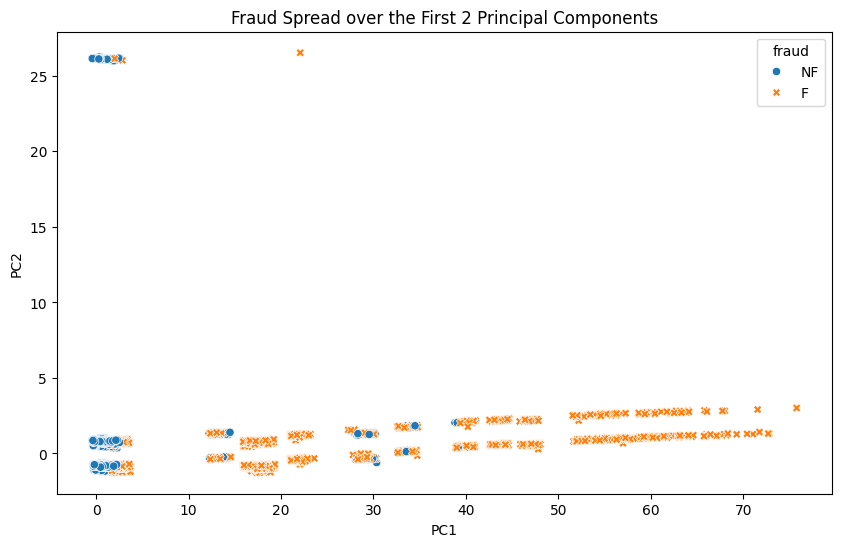

In [ ]:
plt.figure(figsize=(10, 6))
sns.scatterplot(x='PC1', y='PC2', hue='fraud', style='fraud', data=pca_df)
plt.title('Fraud Spread over the First 2 Principal Components')
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show() 

In [19]:
print("Explained variance ratio:", pca.explained_variance_ratio_)

Explained variance ratio: [0.09923016 0.06098442]


In [20]:
fraud_data = data[data['fraud'] == 'F']
non_fraud_data = data[data['fraud'] == 'NF']

In [21]:
non_fraud_sample = non_fraud_data.sample(frac=0.0166, random_state=123)  # Approx 9647 non-fraud samples
undersampling_data = pd.concat([non_fraud_sample, fraud_data]).sample(frac=1, random_state=123)
print("Undersampling data dimensions:", undersampling_data.shape)

Undersampling data dimensions: (16943, 43)


In [26]:
X = undersampling_data.drop('fraud', axis=1)
y = undersampling_data['fraud']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=123, stratify=y)

# Convert string labels to numerical labels
y_train = y_train.map({'F': 1, 'NF': 0})
y_test = y_test.map({'F': 1, 'NF': 0})

In [27]:
rf_model = RandomForestClassifier(random_state=123)
xgb_model = XGBClassifier(random_state=123, use_label_encoder=False, eval_metric='logloss')